# HSA_Cam_B_039_numpyro.py

## paramEKLD DOE  

repeat of B_30 but using Mo_B_039 with relative error model and jax/numpyro inference

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import ICIW_Plots

In [2]:
from HSA_Cam_B_039_numpyro import (
    kl_divergence_between_models,
)
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [3]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    return fig, ax

In [4]:
exp_run_name = "agitated-health"  # VI
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [5]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [6]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [7]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [8]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [9]:
display(proposals)

array([[4.50000000e+02, 9.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 5.00000007e-02],
       [5.72409668e+02, 9.00000000e+00, 2.00000003e-01, 5.00000000e-01,
        1.00000000e+03, 1.00000000e+00],
       [6.00000000e+02, 4.55595636e+00, 2.55976033e+00, 7.34612061e+02,
        1.00000000e+03, 5.00000007e-02],
       [4.77540131e+02, 6.34565020e+00, 3.73404837e+00, 2.79569885e+02,
        8.77789490e+02, 1.00000000e+00],
       [5.46617004e+02, 8.54242611e+00, 4.00000000e+00, 1.00000000e+03,
        5.00000000e-01, 1.00000000e+00],
       [6.00000000e+02, 9.00000000e+00, 4.00000000e+00, 5.00000000e-01,
        1.00000000e+03, 1.00000000e+00],
       [4.50000000e+02, 3.00000000e+00, 3.90871453e+00, 5.00000000e-01,
        5.00000000e-01, 5.00000007e-02],
       [6.00000000e+02, 3.00000000e+00, 2.00000003e-01, 3.37680893e+01,
        5.00000000e-01, 5.00000007e-02],
       [4.65268677e+02, 3.00000000e+00, 4.00000000e+00, 1.00000000e+03,
        1.00000000e+03, 

### Display the results:

In [13]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
        # ylim=(5e-6, 5e-4),
        # xlim=(450, 600),
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(450, 1500, 100),
    )
    ax.scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

/tmp/ipykernel_96579/2292498082.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



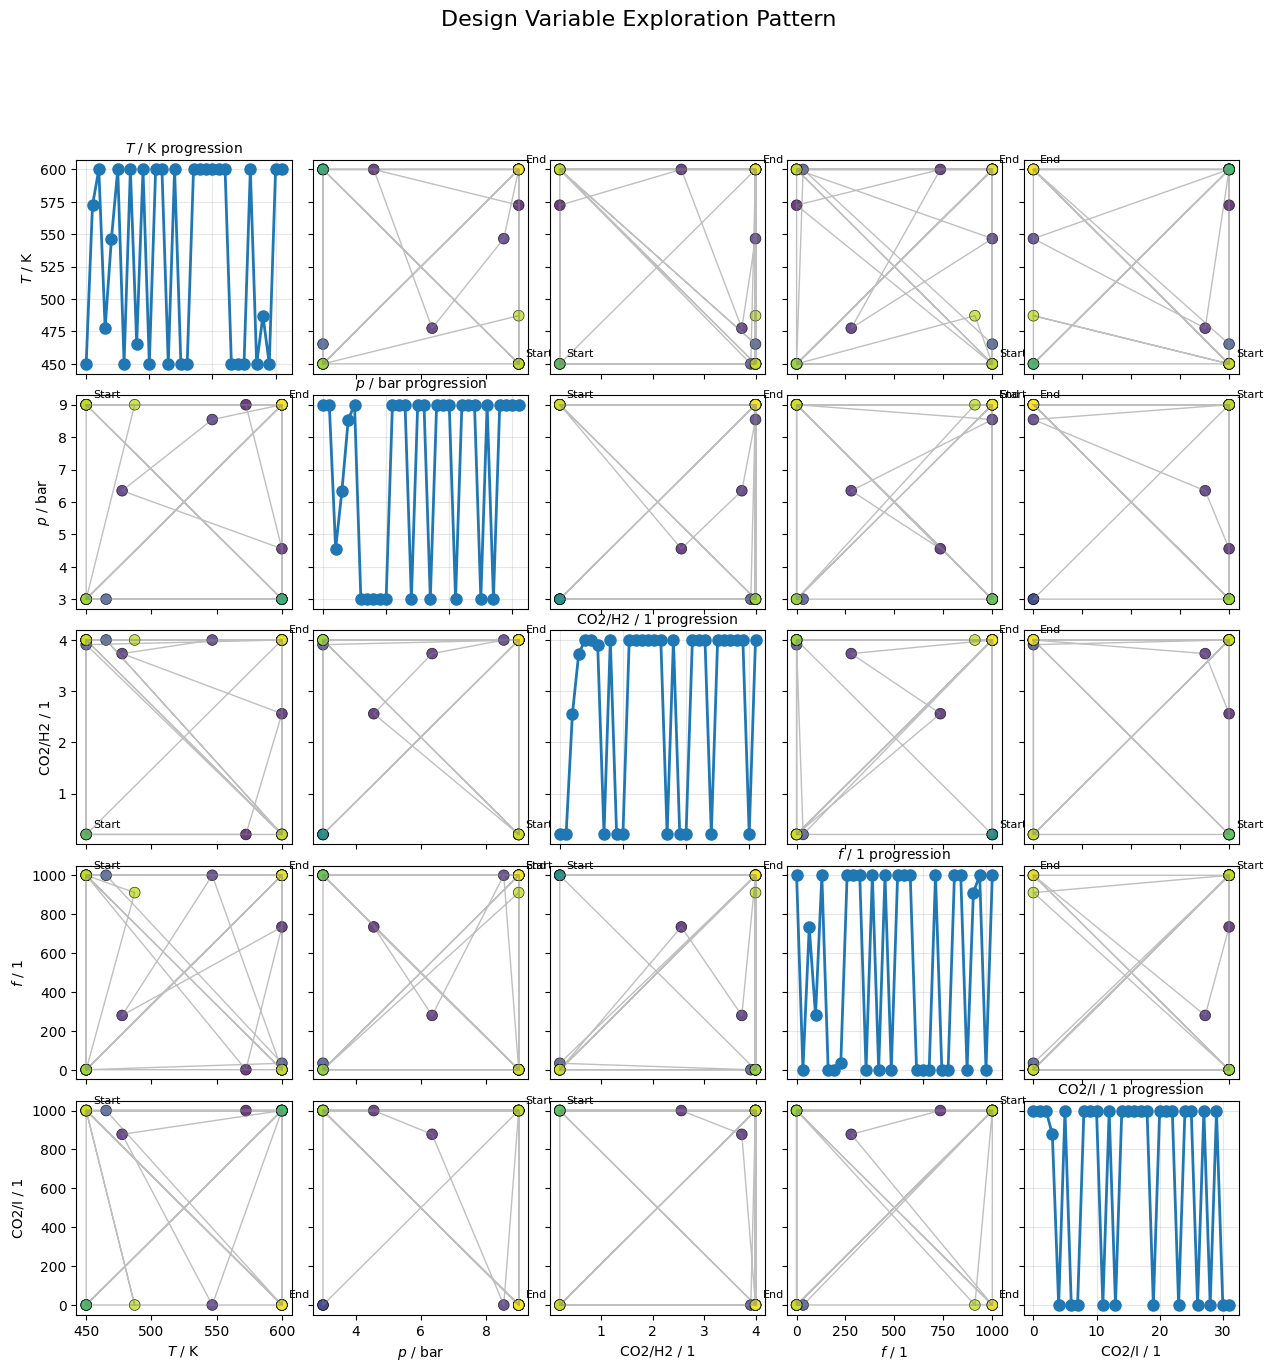

In [11]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [13]:
import xarray

info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[0.03612456 0.26641313 0.03130322 0.01077521 0.04476931 0.00646076
 0.00676201 0.00328946 0.05908514]
0.46498280973514855
[0.1538269  1.22036189 0.00971642 0.02269891 0.10388108 0.01371762
 0.02682364 0.00737273 0.00198376]
1.5603829607584478
[0.39864752 0.02301639 0.00786012 0.01365564 0.83871885 0.01063458
 0.09321114 0.00435889 0.01380137]
1.4039045063496485
[ 0.25752122  0.02677379  0.01706377  0.01645808  0.20683079  0.00412
  0.65485256  0.0099385  -0.0075739 ]
1.185984800430584
[ 0.0590228   0.03541547  1.61764398 -0.01511586  0.05951786  0.09568912
  0.05040859  0.02172102 -0.04117419]
1.8831287816584308
[0.17837921 0.01778086 0.05187753 0.05471407 0.0163909  0.11351556
 0.34800966 0.12962901 0.07519743]
0.985494231571895
[0.0664188  0.12188729 0.10595781 0.0904794  0.04625677 0.05682897
 0.04294319 0.0453652  0.04049367]
0.6166311025773635
[0.20541449 0.04103672 0.11938385 0.10613015 0.11432695 0.09586908
 0.22173264 0.03566389 0.13119303]
1.070750798060162
[0.13551742 0.45042

In [14]:
expected_KLDs = [
    trial["next_proposal"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per KL divergence')

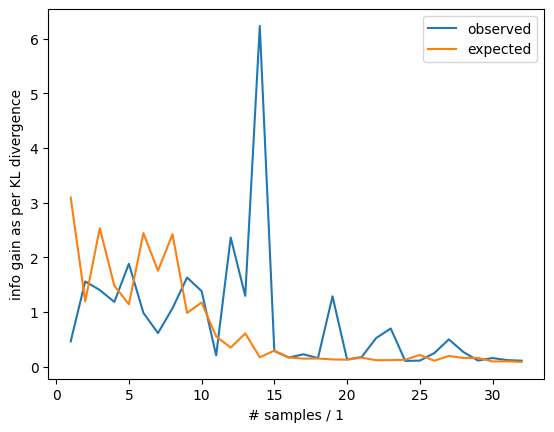

In [15]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.plot(np.arange(len(kldses)) + 1, expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

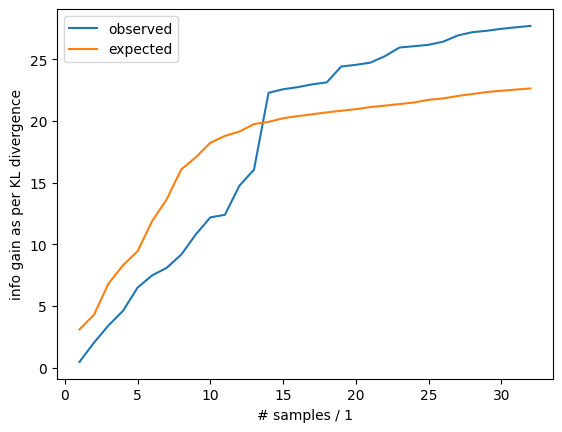

In [33]:
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(kldses), label="observed")
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(expected_KLDs), label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

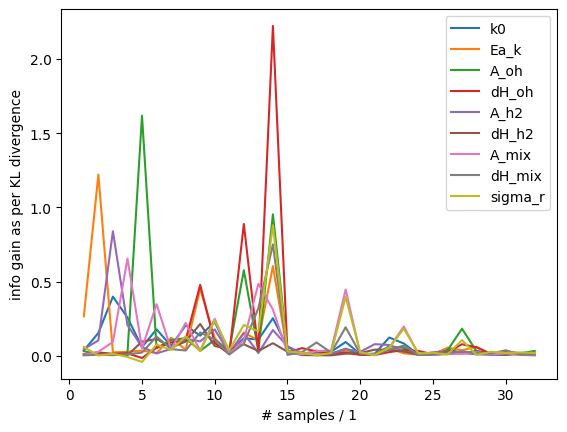

In [16]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [17]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['A_h2', 'A_mix', 'A_oh', 'Ea_k', 'dH_h2', 'dH_mix', 'dH_oh', 'k0', 'r_pred', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', index=7, options=('A_h2', 'A_mix', 'A_oh', 'Ea_k', 'd…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Dropdown(description='Parameter:',…

In [19]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [20]:
az.summary(idatas[-1], round_to=5)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
A_h2,0.39874,0.04310,0.32013,0.48206,0.00025,0.00027,29297.14598,20577.95400,1.00030
A_mix,0.88759,0.06359,0.76726,1.00740,0.00036,0.00039,31867.17365,22169.13133,1.00040
A_oh,0.49587,0.02556,0.44796,0.54440,0.00014,0.00016,33962.71746,20855.95843,1.00024
Ea_k,77854.90625,1819.72705,74380.53125,81239.64062,10.26529,10.93693,31765.14781,21647.51381,1.00013
dH_h2,-10175.03418,2476.13745,-14753.24121,-5435.65088,13.71308,14.24460,32740.53397,23938.73703,1.00023
dH_mix,-7173.82861,1954.51880,-10894.47949,-3487.87134,11.16046,11.51419,30782.06786,23268.90165,1.00012
dH_oh,21240.23633,2187.04053,17143.99023,25419.32031,12.01604,14.04907,33159.78985,21108.79420,1.00019
k0,0.00034,0.00002,0.00030,0.00038,0.00000,0.00000,33380.19343,22255.31328,1.00038
r_pred[0],0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,31996.25743,20199.24430,1.00014
r_pred[1],0.00018,0.00001,0.00016,0.00019,0.00000,0.00000,30824.40598,18450.76934,0.99997


## load the holdout data

In [21]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_B_002.nc"))
display(test_data)

<xarray.Dataset> Size: 120kB
Dimensions:    (sample: 1000, parameter: 6, species: 5)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float64 8kB ...
    p          (sample, species) float64 40kB ...
    latent_r   (sample) float64 8kB ...
    obs_r      (sample) float64 8kB ...
Attributes:
    noise:    heteroscedastic
    sigma:    0.05

In [22]:
postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(
        idata=idata,
        holdout=test_data,
        num_samples=985,
    )
    postdatas.append(postdata)

(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(1, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(2, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(3, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post s

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(5, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(6, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(7, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(8, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(9, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None


...

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(29, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(30, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(31, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)
(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(32, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [23]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_ppc(
        postdatas[i],
        num_pp_samples=100,
        kind="kde",
        # var_names=["r_pred"],
    )
    ax = plt.gca()
    ax.set_xlim(None, 0.0006)

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [24]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="u_value",
        bpv=True,
        # var_names=["r_pred"],
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [25]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="t_stat",
        bpv=True,
        # var_names=["r_pred"],
        t_stat="mean",
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [26]:
display(postdatas[0])

Inference data with groups:
	> posterior_predictive
	> observed_data

In [27]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="t_stat",
        bpv=True,
        # var_names=["r_pred"],
        t_stat=lambda x: np.median(np.log10(x), axis=0),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [28]:
proposals = test_data.samples.values
r_obs = test_data.obs_r.values
r_lat = test_data.latent_r.values


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(480, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    axs[0].scatter(
        proposals[j, 0], r_lat[j], color="green", label="Latent Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

In [29]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da


RMSEs = {"r": [], "r_pred": []}
for postdata in postdatas:
    RMSE = bRMSE(postdata, "r_pred")
    RMSEs["r_pred"].append(RMSE)
    RMSE = bRMSE(postdata, "r")
    RMSEs["r"].append(RMSE)

RMSEar = {
    "r": np.array([rmse.values for rmse in RMSEs["r"]]),
    "r_pred": np.array([rmse.values for rmse in RMSEs["r_pred"]]),
}

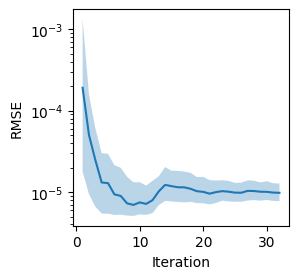

In [30]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r"]) + 1), RMSEar["r"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r"]) + 1),
    np.quantile(RMSEar["r"], 0.025, axis=1),
    np.quantile(RMSEar["r"], 0.975, axis=1),
    alpha=0.3,
)

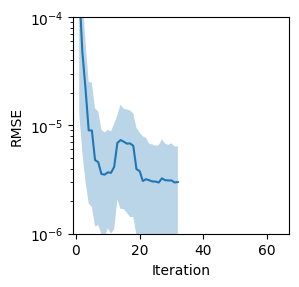

In [31]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)
ax.plot(np.arange(1, len(RMSEar["r_pred"]) + 1), RMSEar["r_pred"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r_pred"]) + 1),
    np.quantile(RMSEar["r_pred"], 0.025, axis=1),
    np.quantile(RMSEar["r_pred"], 0.975, axis=1),
    alpha=0.3,
)

## look at the progression of the parameters

In [ ]:
keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(key):
    means = np.empty((0,))
    lhdi = np.empty((0,))
    uhdi = np.empty((0,))
    for idata in idatas:
        param_samples = idata.posterior[key].values.flatten()
        means = np.append(means, np.mean(param_samples))
        hdi = az.hdi(param_samples, hdi_prob=0.95)
        lhdi = np.append(lhdi, hdi[0])
        uhdi = np.append(uhdi, hdi[1])

    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="Iteration",
        ylabel=f"{key}",
        # yscale="symlog",
    )
    if key != "sigma_r":
        ax.hlines(
            y=TRUE_PARAMS[keydict[key]],
            xmin=1,
            xmax=len(means),
            colors="gray",
            linestyles="dashed",
        )
    ax.plot(np.arange(1, len(means) + 1), means, label="Mean")
    ax.fill_between(
        np.arange(1, len(means) + 1),
        lhdi,
        uhdi,
        alpha=0.3,
        label="95% HDI",
    )
    ax.legend()

interactive(children=(Dropdown(description='Parameter:', index=7, options=('A_h2', 'A_mix', 'A_oh', 'Ea_k', 'd…